# 🛍️ Online Shopping Customer Behaviour: Data Inspection & EDA (Project 3)

## Objective
Understand how customers behave on an online shopping platform by inspecting the data quality and then exploring it visually (**Exploratory Data Analysis**): which product categories are popular, how customers spend, and whether factors like age, time spent or items viewed are related to how much they spend.

## Dataset Overview
- **File:** `online_shopping_customer_behavior.csv`
- **Size:** 1,800 customers × 10 columns (one row per customer)

| Column | Description |
|--------|-------------|
| `customer_id` | Unique ID of each customer (`CUST_1` to `CUST_1800`) |
| `gender` | Gender of the customer (Male / Female) |
| `age` | Age of the customer in years |
| `country` | Country of the customer (6 countries) |
| `device_type` | Device used for shopping (Mobile / Desktop / Tablet) |
| `product_category` | Product category purchased (6 categories) |
| `time_spent_minutes` | Time spent on the platform, in minutes |
| `items_viewed` | Number of items the customer viewed |
| `items_purchased` | Number of items the customer purchased |
| `total_spent_usd` | Total amount spent, in US dollars |

## Notebook Roadmap
**Part A: Data Inspection**
1. Import libraries and load the data
2. Check shape, data types, first and last rows
3. Check for missing values and duplicates
4. Summary statistics
5. Save and download the dataset

**Part B: Exploratory Data Analysis (EDA)**
6. Re-inspect the data and column names
7. Product category analysis (Matplotlib, Seaborn, Plotly)
8. 3D view of age, time spent and total spend
9. Correlation analysis
10. Summary and conclusion

# Part A: Data Inspection

## 1. Import Libraries & Load Data
We use **pandas** for data handling. The CSV file is loaded into a DataFrame called `df` and printed to get a first look at the data.

In [1]:
import pandas as pd
df=pd.read_csv("online_shopping_customer_behavior.csv")
print(df)

     customer_id  gender  age    country device_type product_category  \
0         CUST_1    Male   40  Australia      Tablet         Clothing   
1         CUST_2  Female   38   Pakistan      Tablet      Electronics   
2         CUST_3    Male   36         UK      Tablet         Clothing   
3         CUST_4    Male   36   Pakistan      Mobile         Clothing   
4         CUST_5    Male   53     Canada     Desktop      Electronics   
...          ...     ...  ...        ...         ...              ...   
1795   CUST_1796  Female   62        USA      Mobile         Clothing   
1796   CUST_1797    Male   20        USA     Desktop         Clothing   
1797   CUST_1798  Female   44      India      Mobile      Electronics   
1798   CUST_1799    Male   60   Pakistan      Mobile         Clothing   
1799   CUST_1800    Male   57     Canada      Mobile         Clothing   

      time_spent_minutes  items_viewed  items_purchased  total_spent_usd  
0                     87            12          

## 2. Basic Data Inspection
### 2.1 Shape of the Dataset
`df.shape` returns the number of rows and columns.

**Result:** **1,800 rows and 10 columns**, which means 1,800 customer records.

In [ ]:
df.shape

(1800, 10)

### 2.2 Data Types & Non-Null Counts
`df.info()` shows the data type of each column and how many values are non-null.

**Observations:**
- **5 numeric columns** (`age`, `time_spent_minutes`, `items_viewed`, `items_purchased`, `total_spent_usd`) stored as `int64`.
- **5 text columns** (`customer_id`, `gender`, `country`, `device_type`, `product_category`) stored as `object`.
- Every column has 1,800 non-null values, so the data types are already suitable and no conversion is needed.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   customer_id         1800 non-null   object
 1   gender              1800 non-null   object
 2   age                 1800 non-null   int64 
 3   country             1800 non-null   object
 4   device_type         1800 non-null   object
 5   product_category    1800 non-null   object
 6   time_spent_minutes  1800 non-null   int64 
 7   items_viewed        1800 non-null   int64 
 8   items_purchased     1800 non-null   int64 
 9   total_spent_usd     1800 non-null   int64 
dtypes: int64(5), object(5)
memory usage: 140.8+ KB


### 2.3 First 5 Rows
`df.head()` shows the top rows so we can see what each column contains.

In [ ]:
df.head()

,customer_id,gender,age,country,device_type,product_category,time_spent_minutes,items_viewed,items_purchased,total_spent_usd
0,CUST_1,Male,40,Australia,Tablet,Clothing,87,12,8,1187
1,CUST_2,Female,38,Pakistan,Tablet,Electronics,71,22,3,153
2,CUST_3,Male,36,UK,Tablet,Clothing,59,20,8,1055
3,CUST_4,Male,36,Pakistan,Mobile,Clothing,39,18,3,991
4,CUST_5,Male,53,Canada,Desktop,Electronics,3,1,1,588


### 2.4 Last 5 Rows
`df.tail()` shows the bottom rows to confirm the full dataset has loaded, ending at `CUST_1800`.

In [ ]:
df.tail()

,customer_id,gender,age,country,device_type,product_category,time_spent_minutes,items_viewed,items_purchased,total_spent_usd
1795,CUST_1796,Female,62,USA,Mobile,Clothing,61,30,2,425
1796,CUST_1797,Male,20,USA,Desktop,Clothing,87,12,3,1344
1797,CUST_1798,Female,44,India,Mobile,Electronics,21,35,0,1194
1798,CUST_1799,Male,60,Pakistan,Mobile,Clothing,88,11,3,1231
1799,CUST_1800,Male,57,Canada,Mobile,Clothing,68,44,0,472


## 3. Data Quality Checks
### 3.1 Missing Values
`df.isnull().sum()` counts the null values in each column.

**Result:** All 10 columns have **0 missing values**, so no imputation or row removal is needed.

In [3]:
df.isnull().sum()

,0
customer_id,0
gender,0
age,0
country,0
device_type,0
product_category,0
time_spent_minutes,0
items_viewed,0
items_purchased,0
total_spent_usd,0


### 3.2 Duplicate Records
`df.duplicated().sum()` counts rows that are exact copies of another row.

**Result:** **0 duplicates** found. Every customer record is unique.

In [ ]:
df.duplicated().sum()

np.int64(0)

## 4. Summary Statistics
`df.describe()` gives the count, mean, spread and quartiles of the numeric columns.

| Column | Min | Mean | Max |
|--------|-----|------|-----|
| `age` | 18 | 41.1 | 64 |
| `time_spent_minutes` | 1 | 60.5 | 119 |
| `items_viewed` | 1 | 24.5 | 49 |
| `items_purchased` | 0 | 4.6 | 9 |
| `total_spent_usd` | \$5 | \$778.50 | \$1,499 |

**Observations:**
- Customers are adult shoppers aged **18 to 64**, with an average age of about 41.
- The average customer spends about **\$778**, with a median of **\$802**, so spending is fairly evenly spread.
- Some customers purchased **0 items** (`items_purchased` minimum is 0), so not every visit ends in a purchase.

In [ ]:
df.describe()

,age,time_spent_minutes,items_viewed,items_purchased,total_spent_usd
count,1800.000000,1800.000000,1800.000000,1800.000000,1800.000000
mean,41.144444,60.544444,24.542778,4.606667,778.503333
std,13.481514,34.717237,14.041840,2.852841,434.788777
min,18.000000,1.000000,1.000000,0.000000,5.000000
25%,30.000000,30.000000,13.000000,2.000000,400.750000
50%,41.000000,60.000000,24.000000,5.000000,802.000000
75%,53.000000,91.000000,36.000000,7.000000,1146.250000
max,64.000000,119.000000,49.000000,9.000000,1499.000000


## 5. Save the Dataset
The DataFrame is exported to `online_shopping_customer_behavior.csv`. We use `index=False` so the row index is not saved as an extra column.

> No values were changed because the checks found no missing values or duplicates, so the saved file has the same content as the loaded one.

In [4]:
df.to_csv('online_shopping_customer_behavior.csv', index=False)

### 5.1 Verify: First 5 Rows
A quick look at the top rows to confirm the data is intact after saving.

In [ ]:
df.head()

,customer_id,gender,age,country,device_type,product_category,time_spent_minutes,items_viewed,items_purchased,total_spent_usd
0,CUST_1,Male,40,Australia,Tablet,Clothing,87,12,8,1187
1,CUST_2,Female,38,Pakistan,Tablet,Electronics,71,22,3,153
2,CUST_3,Male,36,UK,Tablet,Clothing,59,20,8,1055
3,CUST_4,Male,36,Pakistan,Mobile,Clothing,39,18,3,991
4,CUST_5,Male,53,Canada,Desktop,Electronics,3,1,1,588


### 5.2 Verify: Last 5 Rows
Confirms the last record (`CUST_1800`) is still present.

In [ ]:
df.tail()

,customer_id,gender,age,country,device_type,product_category,time_spent_minutes,items_viewed,items_purchased,total_spent_usd
1795,CUST_1796,Female,62,USA,Mobile,Clothing,61,30,2,425
1796,CUST_1797,Male,20,USA,Desktop,Clothing,87,12,3,1344
1797,CUST_1798,Female,44,India,Mobile,Electronics,21,35,0,1194
1798,CUST_1799,Male,60,Pakistan,Mobile,Clothing,88,11,3,1231
1799,CUST_1800,Male,57,Canada,Mobile,Clothing,68,44,0,472


### 5.3 Download the File
Downloads the CSV file to the local machine (Google Colab).

In [5]:
from google.colab import files

files.download('online_shopping_customer_behavior.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Part B: Exploratory Data Analysis (EDA)

EDA means exploring the data with summary statistics and charts to understand its patterns before any deeper analysis. In this part we look at the product categories, the relationship between age, time spent and spending, and the correlation between the numeric columns.

## 6. Re-check the Data
### 6.1 First 5 Rows
A fresh look at the data at the start of the EDA.

In [ ]:
df.head()


,customer_id,gender,age,country,device_type,product_category,time_spent_minutes,items_viewed,items_purchased,total_spent_usd
0,CUST_1,Male,40,Australia,Tablet,Clothing,87,12,8,1187
1,CUST_2,Female,38,Pakistan,Tablet,Electronics,71,22,3,153
2,CUST_3,Male,36,UK,Tablet,Clothing,59,20,8,1055
3,CUST_4,Male,36,Pakistan,Mobile,Clothing,39,18,3,991
4,CUST_5,Male,53,Canada,Desktop,Electronics,3,1,1,588


### 6.2 Shape
Confirms the dataset is still **1,800 rows × 10 columns**.

In [ ]:
df.shape


(1800, 10)

### 6.3 Data Types
Same structure as before: 5 numeric and 5 text columns, with no missing values.

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1800 entries, 0 to 1799
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   customer_id         1800 non-null   object
 1   gender              1800 non-null   object
 2   age                 1800 non-null   int64 
 3   country             1800 non-null   object
 4   device_type         1800 non-null   object
 5   product_category    1800 non-null   object
 6   time_spent_minutes  1800 non-null   int64 
 7   items_viewed        1800 non-null   int64 
 8   items_purchased     1800 non-null   int64 
 9   total_spent_usd     1800 non-null   int64 
dtypes: int64(5), object(5)
memory usage: 140.8+ KB


### 6.4 Summary of All Columns
`df.describe(include="all")` summarises the text columns as well as the numeric ones.

**Observations:**
- `customer_id` has **1,800 unique values**, so each row is a different customer.
- **Gender:** 2 values; Male is the most frequent with 911 customers (about 50.6%), so the genders are almost evenly split.
- **Country:** 6 countries; **Pakistan** appears most often with 330 customers (about 18.3%).
- **Device type:** 3 devices; **Tablet** is the most used with 637 customers (about 35.4%).
- **Product category:** 6 categories; **Clothing** is the most frequent with 345 customers (about 19.2%).

In [ ]:
df.describe(include="all")


,customer_id,gender,age,country,device_type,product_category,time_spent_minutes,items_viewed,items_purchased,total_spent_usd
count,1800,1800,1800.000000,1800,1800,1800,1800.000000,1800.000000,1800.000000,1800.000000
unique,1800,2,NaN,6,3,6,NaN,NaN,NaN,NaN
top,CUST_1800,Male,NaN,Pakistan,Tablet,Clothing,NaN,NaN,NaN,NaN
freq,1,911,NaN,330,637,345,NaN,NaN,NaN,NaN
mean,NaN,NaN,41.144444,NaN,NaN,NaN,60.544444,24.542778,4.606667,778.503333
std,NaN,NaN,13.481514,NaN,NaN,NaN,34.717237,14.041840,2.852841,434.788777
min,NaN,NaN,18.000000,NaN,NaN,NaN,1.000000,1.000000,0.000000,5.000000
25%,NaN,NaN,30.000000,NaN,NaN,NaN,30.000000,13.000000,2.000000,400.750000
50%,NaN,NaN,41.000000,NaN,NaN,NaN,60.000000,24.000000,5.000000,802.000000
75%,NaN,NaN,53.000000,NaN,NaN,NaN,91.000000,36.000000,7.000000,1146.250000


### 6.5 Column Names
Lists all column names for easy reference while writing the charts below.

In [ ]:
print(df.columns.tolist())

['customer_id', 'gender', 'age', 'country', 'device_type', 'product_category', 'time_spent_minutes', 'items_viewed', 'items_purchased', 'total_spent_usd']


## 7. Product Category Analysis
The next three charts show the same thing, the number of customers in each product category, built with three different libraries.

### 7.1 Bar Chart (Matplotlib)
`value_counts()` counts the customers per category, and a bar chart with labels on top shows the counts.

**Insights:**
- **Clothing** is the most popular category with **345** customers, followed by **Sports** (311).
- **Electronics** and **Books** are tied at **294** each, followed by **Beauty** (283).
- **Home** is the least popular with **273** customers.
- The gap between the top and bottom category is small (345 vs 273), so customers are spread fairly evenly across all six categories.

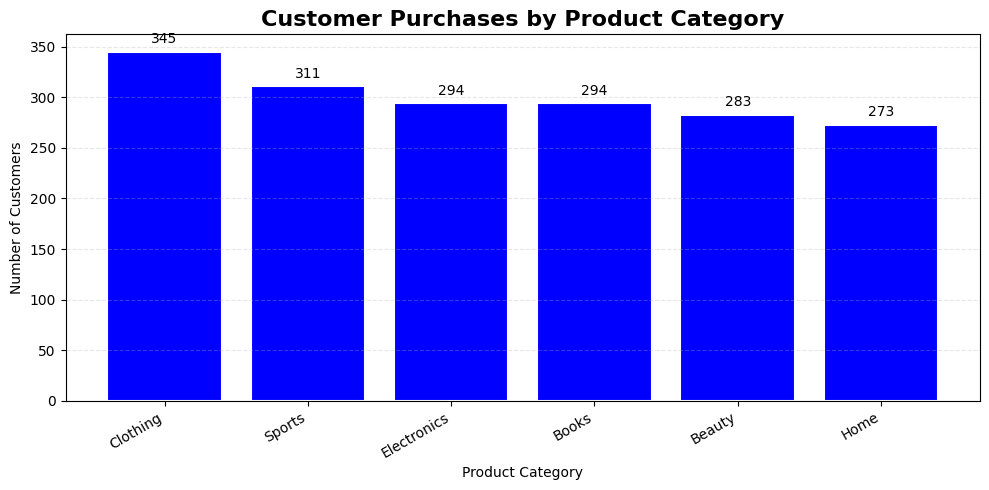

In [ ]:
import matplotlib.pyplot as plt

category_counts = df['product_category'].value_counts()

plt.figure(figsize=(10, 5))
bars = plt.bar(
    category_counts.index,
    category_counts.values,
    color='blue',
    edgecolor='white',
    linewidth=1.5
)

plt.bar_label(bars, padding=4, fontsize=10)
plt.title('Customer Purchases by Product Category',
          fontsize=16, fontweight='bold')
plt.xlabel('Product Category')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

### 7.2 Count Plot (Seaborn)
The same distribution drawn with Seaborn's `countplot`, with the categories ordered from most to least frequent. It gives a cleaner look with the `mako` colour palette.

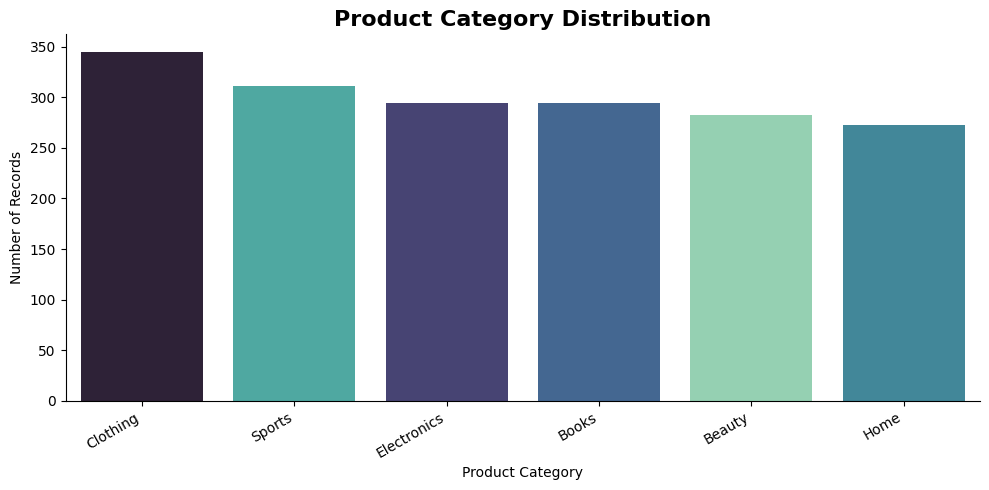

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='product_category',
    order=df['product_category'].value_counts().index,
    hue='product_category',
    palette='mako',
    legend=False
)

plt.title('Product Category Distribution',
          fontsize=16, fontweight='bold')
plt.xlabel('Product Category')
plt.ylabel('Number of Records')
plt.xticks(rotation=30, ha='right')
sns.despine()
plt.tight_layout()
plt.show()

### 7.3 Interactive Bar Chart (Plotly)
An interactive version of the same chart. Hovering over a bar shows the exact count, and the colour gets darker as the count increases.

In [ ]:
import plotly.express as px

category_counts = (
    df['product_category']
    .value_counts()
    .rename_axis('Product Category')
    .reset_index(name='Count')
)

fig = px.bar(
    category_counts,
    x='Product Category',
    y='Count',
    color='Count',
    text='Count',
    color_continuous_scale='Purples',
    title='Interactive Customer Shopping Analysis',
    template='plotly_dark'
)

fig.update_traces(textposition='outside')
fig.update_layout(
    title_x=0.5,
    height=550,
    xaxis_title='Product Category',
    yaxis_title='Number of Records'
)

fig.show()

## 8. Customer Behaviour in 3D
### 8.1 Interactive 3D Scatter Plot (Plotly)
Each point is one customer, plotted by **age** (x), **time spent** (y) and **total spent** (z). The colour shows gender and the point size shows the number of items purchased. The plot can be rotated and zoomed to look for any visible groups or patterns.

In [ ]:
import plotly.express as px

fig = px.scatter_3d(
    df,
    x='age',
    y='time_spent_minutes',
    z='total_spent_usd',
    color='gender',
    size='items_purchased',
    title='3D Customer Shopping Behaviour',
    template='plotly_dark'
)

fig.show()

### 8.2 3D Scatter Plot (Matplotlib)
A static 3D version of the same idea. The colour of each point shows **total spent (USD)**, so higher spenders can be spotted easily using the colour bar.

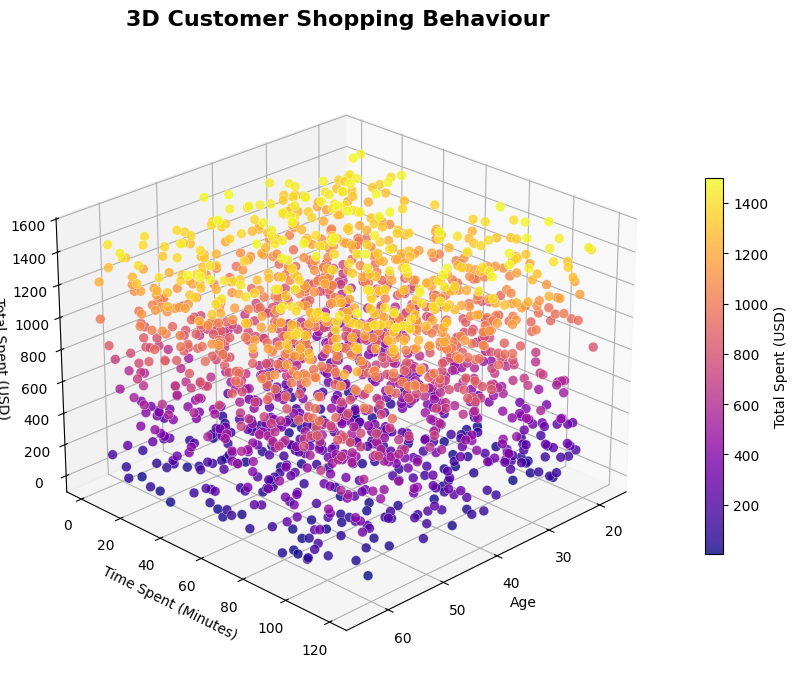

In [ ]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(
    df['age'],
    df['time_spent_minutes'],
    df['total_spent_usd'],
    c=df['total_spent_usd'],
    cmap='plasma',
    s=50,
    alpha=0.8,
    edgecolor='white',
    linewidth=0.3
)

ax.set_title('3D Customer Shopping Behaviour',
             fontsize=16, fontweight='bold', pad=20)

ax.set_xlabel('Age')
ax.set_ylabel('Time Spent (Minutes)')
ax.set_zlabel('Total Spent (USD)')

fig.colorbar(scatter, ax=ax, shrink=0.6, label='Total Spent (USD)')
ax.view_init(elev=25, azim=45)

plt.tight_layout()
plt.show()

## 9. Correlation Analysis
A **correlation** value between -1 and +1 shows how strongly two numeric columns move together (+1 = move together, -1 = move in opposite directions, 0 = no linear relationship). The heatmap shows this for all five numeric columns.

**Insights:**
- All correlations between different columns are **very close to 0** (between -0.02 and 0.03).
- **Total spent** has almost no linear relationship with age (0.03), time spent (0.01), items viewed (0.02) or items purchased (0.03).
- This means that spending more time on the platform, viewing more items or being older does **not** by itself predict higher spending in this dataset.
- Since the relationships are so weak, other factors such as product category, device or country may be worth exploring in the next steps.

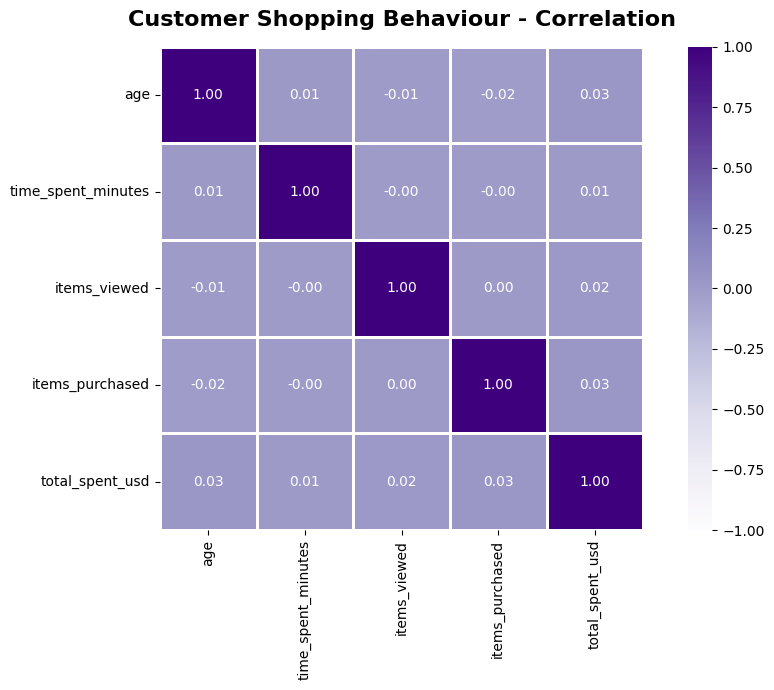

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

num_cols = [
    'age',
    'time_spent_minutes',
    'items_viewed',
    'items_purchased',
    'total_spent_usd'
]

corr = df[num_cols].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    corr,
    annot=True,
    cmap='Purples',
    fmt='.2f',
    linewidths=1,
    square=True,
    vmin=-1,
    vmax=1
)

plt.title('Customer Shopping Behaviour - Correlation',
          fontsize=16, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()


---
## ✅ Summary & Conclusion

| Check | Result |
|-------|--------|
| Rows × Columns | 1,800 × 10 |
| Data types | 5 numeric, 5 text |
| Missing values | None |
| Duplicate rows | None |
| Most popular category | Clothing (345 customers), least popular: Home (273) |
| Most common country / device | Pakistan (330) / Tablet (637) |
| Average spend per customer | About \$778 (range \$5 to \$1,499) |
| Correlations with total spend | All close to 0 (0.01 to 0.03) |
| Output file | `online_shopping_customer_behavior.csv` |

**Conclusion:** The dataset is clean and complete, with no missing values or duplicates. Customers are spread fairly evenly across the six product categories, with Clothing leading. The most notable finding is that **age, time spent, items viewed and items purchased show almost no correlation with how much a customer spends**, so simple behaviour numbers do not explain spending here.